# 05 KG-structured attribute prompts for zero-shot dermatology

**Idea.** Instead of compressing a disease's knowledge into one prompt (CLIP truncates at 77 tokens), every KG attribute becomes its own sentence, e.g. *"psoriasis, which shows scale"*, *"psoriasis, on the extensor surfaces"*. An image is matched against every sentence. Within each relation type the matches are pooled with a learnable temperature (mean when large, max when small: an image often shows only some attributes), and the types are combined with learned weights:
$$s_d(x)=\frac{\sum_r m_{dr}\,\omega_r\,\tau_r\Big[\log\sum_{k\in K_{dr}} e^{\langle x,e_k\rangle/\tau_r}-\log|K_{dr}|\Big]}{\sum_r m_{dr}\,\omega_r},\qquad \omega=\operatorname{softmax}(\theta)$$
Only ~20 class-agnostic parameters are learned (one weight and one temperature per relation type, one scale), on seen diseases, and applied unchanged to unseen diseases.

**Controls.** *Shuffled KB*: attribute sets permuted across diseases within each type, sentences rebuilt with the true disease name. If this does as well, the gain is prompt ensembling, not knowledge. *Description mean*: all sentences averaged without KG structure (DCLIP-style).

Splits 0-4 are identical to `04` v2. Validation, calibration and the pseudo-unseen protocol are the same. Results in `results_v2c/`, figures in `figures_v2c/`.

`pip install torch transformers pandas numpy scipy scikit-learn matplotlib pillow tqdm`

In [1]:
# ============ Config ============
import os
from pathlib import Path
os.environ['HF_HUB_DISABLE_SYMLINKS_WARNING'] = '1'

DATA = Path('data_v2'); FEAT = DATA / 'features'; KG = DATA / 'kg'
KB_CSV = Path('dermkb.csv'); MODEL_DIR = Path('models') / 'monet'
RES, FIG = Path('results_v2c'), Path('figures_v2c')
BACKBONE, OURS = 'monet', 'Ours'

N_SPLITS, UNSEEN_FRAC, VAL_FRAC = 10, 0.20, 0.20
EPOCHS, BATCH, LR = 20, 512, 0.05
ZSL_METHODS = ['name', 'kg_text', 'desc_mean', 'types_equal', 'ours', 'ours_shuffled_kb']
ABLATION = True
N_CASES = 3
QUICK, FORCE = False, False
if QUICK:
    N_SPLITS, EPOCHS, RES = 2, 5, Path('results_v2c_quick')
for d in (RES, FIG):
    d.mkdir(parents=True, exist_ok=True)

In [2]:
import json, math, re, time, copy
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image
from scipy.stats import ttest_rel
from tqdm.auto import tqdm

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 8, 'axes.spines.top': False,
                     'axes.spines.right': False, 'savefig.bbox': 'tight', 'savefig.dpi': 300})
NAMES = {'name': 'MONET zero-shot (name)', 'kg_text': 'MONET zero-shot (KG text)',
         'desc_mean': 'Description mean (no KG structure)', 'types_equal': 'KG types, equal weights',
         'ours': OURS, 'ours_shuffled_kb': f'{OURS}, shuffled KB'}
PAL = {'name': '#bdbdbd', 'kg_text': '#8c8c8c', 'desc_mean': '#a6cee3', 'types_equal': '#1f78b4',
       'ours': '#c1121f', 'ours_shuffled_kb': '#e9c46a'}
TYPES = ['name', 'full', 'primary', 'secondary', 'color', 'configuration', 'location', 'etiology', 'symptom',
         'category', 'description']
TYPE_COL = {'name': '#4d4d4d', 'full': '#8c8c8c', 'primary': '#2a6f97', 'secondary': '#61a5c2', 'color': '#f4a261',
            'configuration': '#2a9d8f', 'location': '#8ab17d', 'etiology': '#e9c46a', 'symptom': '#bc6c25',
            'category': '#6a4c93', 'description': '#c1121f'}

def savefig(fig, name):
    for ext in ('pdf', 'png'):
        fig.savefig(FIG / f'{name}.{ext}')
    print('saved', FIG / f'{name}.pdf')
print('device:', DEVICE)

device: cuda


c:\Users\78479\anaconda3\envs\skin311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Data

In [3]:
meta = pd.read_csv(DATA / 'meta.csv')
tax = pd.read_csv(DATA / 'taxonomy.csv').sort_values('disease_id').reset_index(drop=True)
Cn, y = len(tax), meta['disease_id'].to_numpy()
dname, cat_of = tax['disease'].to_numpy(), tax['category'].to_numpy()
split_lt = meta['split_lt'].to_numpy()
img_path = meta['cache_path'].where(meta['cache_path'].notna(), meta['path']).to_numpy()
Xt = F.normalize(torch.from_numpy(np.load(FEAT / BACKBONE / 'image.npy').astype(np.float32)), dim=-1).to(DEVICE)
full_text = pd.read_csv(KG / 'disease_text.csv').sort_values('disease_id')['full_text'].tolist()

kb = pd.read_csv(KB_CSV).fillna('')
alias2kb = {d: d for d in kb['disease']}
for d, a in zip(kb['disease'], kb['aliases']):
    for x in [s.strip() for s in a.split(';') if s.strip()]:
        alias2kb[x] = d
kbi = kb.set_index('disease')
split_ = lambda s: [x.strip() for x in str(s).split(';') if x.strip()]
print(f'{len(meta)} images | {Cn} diseases | image dim {Xt.shape[1]}')

16321 images | 114 diseases | image dim 768


## 2. Attribute sentences

In [4]:
PLURAL = {'macule': 'macules', 'patch': 'patches', 'papule': 'papules', 'plaque': 'plaques', 'nodule': 'nodules',
          'tumor': 'tumors', 'cyst': 'cysts', 'vesicle': 'vesicles', 'bulla': 'bullae', 'pustule': 'pustules',
          'wheal': 'wheals', 'comedo': 'comedones', 'burrow': 'burrows', 'telangiectasia': 'telangiectasias',
          'purpura': 'purpura'}
LOC = {'generalized': 'the whole body', 'sun-exposed': 'sun-exposed skin', 'intertriginous': 'the skin folds',
       'flexural': 'the flexures', 'extensor': 'the extensor surfaces', 'periorificial': 'the skin around the orifices',
       'perioral': 'the skin around the mouth', 'upper extremities': 'the arms', 'lower extremities': 'the legs'}
ETIO = {'infectious-bacterial': 'bacterial', 'infectious-viral': 'viral', 'infectious-parasitic': 'parasitic',
        'neoplastic-benign': 'benign neoplastic', 'neoplastic-malignant': 'malignant',
        'neoplastic-premalignant': 'premalignant', 'photo-induced': 'light-induced', 'hamartoma': 'hamartomatous'}
SYMP = {'pruritus': 'itchy', 'pain': 'painful', 'tenderness': 'tender', 'burning': 'burning', 'bleeding': 'bleeding',
        'asymptomatic': 'asymptomatic'}
TEMPLATE = {
    'primary':       lambda n, v: f'a clinical photograph of {n}, which shows {PLURAL.get(v, v)}',
    'secondary':     lambda n, v: f'a clinical photograph of {n}, which shows {v}',
    'color':         lambda n, v: f'a clinical photograph of {n}, which looks {v}',
    'configuration': lambda n, v: f'a clinical photograph of {n}, with lesions in a {v} arrangement',
    'location':      lambda n, v: f'a clinical photograph of {n}, on {LOC.get(v, "the " + v)}',
    'etiology':      lambda n, v: f'a clinical photograph of {n}, a {ETIO.get(v, v)} skin condition',
    'symptom':       lambda n, v: f'a clinical photograph of {n}, which is {SYMP.get(v, v)}',
}

def kb_entry(d):
    return kbi.loc[alias2kb[d]]

def build_sentences(attr_source=None):
    # attr_source: disease_id -> disease_id whose attributes are used (None = own attributes)
    rows = []
    for i, n in enumerate(dname):
        e = kb_entry(n)
        rows.append((i, 'name', f'a clinical photograph of {n}', n))
        rows.append((i, 'full', full_text[i], ''))
        rows.append((i, 'category', f'a clinical photograph of {n}, a {cat_of[i]} skin lesion', cat_of[i]))
        src = kb_entry(dname[attr_source[i]]) if attr_source is not None else e
        for f, tmpl in TEMPLATE.items():
            for v in split_(src[f]):
                rows.append((i, f, tmpl(n, v), v))
        for s in re.split(r'(?<=[.!?])\s+', src['description']):
            if s.strip():
                rows.append((i, 'description', f'{n}: {s.strip()}', s.strip()))
    return pd.DataFrame(rows, columns=['disease_id', 'type', 'text', 'value'])

SENT = build_sentences()
print(SENT.groupby('type').size().reindex(TYPES).to_string())
print(f'\n{len(SENT)} sentences, {len(SENT) / Cn:.1f} per disease. Examples:')
print('\n'.join(SENT[SENT['disease_id'] == 0]['text'].head(8)))

type
name             114
full             114
primary          236
secondary        151
color            230
configuration    135
location         286
etiology         147
symptom          134
category         114
description      114

1775 sentences, 15.6 per disease. Examples:
a clinical photograph of becker nevus
becker nevus is a hamartoma skin condition in the benign dermal group. Lesions are brown and hyperpigmented patch and plaque with hypertrichosis. Arrangement: solitary and unilateral. Typical sites: trunk and upper extremities. Symptoms: asymptomatic. Unilateral brown patch on the shoulder or upper trunk, often with increased hair, appearing in adolescent males.
a clinical photograph of becker nevus, a benign dermal skin lesion
a clinical photograph of becker nevus, which shows patches
a clinical photograph of becker nevus, which shows plaques
a clinical photograph of becker nevus, which shows hypertrichosis
a clinical photograph of becker nevus, which looks brown
a clinic

## 3. Encode sentences with the MONET text encoder (cached)

In [5]:
from transformers import AutoModel, AutoTokenizer
_enc = {}
def text_model():
    if not _enc:
        _enc['m'] = AutoModel.from_pretrained(MODEL_DIR).to(DEVICE).eval()
        _enc['t'] = AutoTokenizer.from_pretrained(MODEL_DIR)
    return _enc['m'], _enc['t']

@torch.no_grad()
def encode(texts, bs=128):
    m, tok = text_model(); out = []
    for i in range(0, len(texts), bs):
        t = tok(texts[i:i + bs], padding=True, truncation=True, max_length=77, return_tensors='pt').to(DEVICE)
        f = m.get_text_features(**t)
        f = f if torch.is_tensor(f) else f.pooler_output
        out.append(F.normalize(f.float(), dim=-1))
    return torch.cat(out)

def cached_embeddings(df, tag):
    f = RES / f'sent_{tag}.npy'
    if f.exists() and not FORCE and len(np.load(f)) == len(df):
        return torch.from_numpy(np.load(f)).to(DEVICE)
    E = encode(df['text'].tolist()); np.save(f, E.cpu().numpy()); return E

E_OWN = cached_embeddings(SENT, 'own')
SENT.to_csv(RES / 'sentences.csv', index=False)
print('embeddings:', tuple(E_OWN.shape))

W1121 04:06:24.927000 41272 site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.
Loading weights: 100%|██████████| 590/590 [00:01<00:00, 371.55it/s]


embeddings: (1775, 768)


## 4. Scorer

In [6]:
def pack(df):
    # per type: [Cn, max_k] sentence index matrix with mask; m[d, r] = disease has sentences of type r
    idx, msk, has = [], [], torch.zeros(Cn, len(TYPES), dtype=torch.bool)
    for r, t in enumerate(TYPES):
        g = df[df['type'] == t].groupby('disease_id').apply(lambda s: list(s.index), include_groups=False)
        K = max([len(v) for v in g] + [1])
        I = torch.zeros(Cn, K, dtype=torch.long); M = torch.zeros(Cn, K, dtype=torch.bool)
        for d, v in g.items():
            I[d, :len(v)] = torch.tensor(v); M[d, :len(v)] = True; has[d, r] = True
        idx.append(I.to(DEVICE)); msk.append(M.to(DEVICE))
    return idx, msk, has.to(DEVICE)

class Scorer(nn.Module):
    def __init__(self, E, packed, use_types, learn=True, flat=False):
        super().__init__()
        self.E, (self.idx, self.msk, has) = E, packed
        self.flat = flat
        on = torch.tensor([t in use_types for t in TYPES], device=DEVICE)
        self.register_buffer('m', (has & on[None, :]).float())
        self.theta = nn.Parameter(torch.zeros(len(TYPES)), requires_grad=learn)
        self.log_tau = nn.Parameter(torch.full((len(TYPES),), math.log(1.0)), requires_grad=learn)
        self.log_scale = nn.Parameter(torch.tensor(math.log(100.0)), requires_grad=learn)
        if flat:     # all non-name sentences of a disease in one pool, plain mean
            keep = torch.tensor([t not in ('name', 'full') for t in TYPES], device=DEVICE)
            self.flat_m = keep

    def type_scores(self, x):
        S = x @ self.E.T                                                   # [B, K_all]
        out = []
        for r in range(len(TYPES)):
            s = S[:, self.idx[r]]                                          # [B, Cn, k]
            tau = self.log_tau[r].exp().clamp(0.01, 10.0)
            s = (s / tau).masked_fill(~self.msk[r][None], float('-inf'))
            cnt = self.msk[r].sum(1).clamp(min=1).float()
            out.append(tau * (torch.logsumexp(s, -1) - torch.log(cnt)[None]))
        return torch.nan_to_num(torch.stack(out, -1), neginf=0.0)          # [B, Cn, R]

    def forward(self, x):
        if self.flat:
            S = x @ self.E.T
            tot = sum((S[:, self.idx[r]] * self.msk[r][None]).sum(-1) for r in range(len(TYPES)) if self.flat_m[r])
            cnt = sum(self.msk[r].sum(1) for r in range(len(TYPES)) if self.flat_m[r]).clamp(min=1)
            return self.log_scale.exp() * tot / cnt[None]
        w = torch.softmax(self.theta, 0)[None, :] * self.m                # [Cn, R]
        s = (self.type_scores(x) * w[None]).sum(-1) / w.sum(-1).clamp(min=1e-8)[None]
        return self.log_scale.exp() * s

@torch.no_grad()
def predict(model, idx, bs=1024):
    return torch.cat([model(Xt[torch.as_tensor(i, device=DEVICE)]) for i in np.array_split(idx, max(1, len(idx) // bs))]).cpu()

PACK_OWN = pack(SENT)
ATTR_TYPES = ['primary', 'secondary', 'color', 'configuration', 'location', 'etiology', 'symptom', 'category', 'description']

## 5. Splits and metrics (same protocol as 04 v2)

In [7]:
def zsl_split(k):
    if k == 0:
        unseen = np.sort(meta.loc[meta['unseen'], 'disease_id'].unique())
    else:
        rng = np.random.default_rng(1000 + k); unseen = []
        for _, g in tax.groupby('category'):
            n = len(g); m = min(max(int(round(UNSEEN_FRAC * n)), 1 if n >= 3 else 0), n - 1)
            unseen += rng.choice(g['disease_id'].to_numpy(), m, replace=False).tolist()
        unseen = np.sort(unseen)
    seen = np.setdiff1d(np.arange(Cn), unseen)
    s_val = np.sort(np.random.default_rng(2000 + k).choice(seen, max(2, int(round(VAL_FRAC * len(seen)))), replace=False))
    s_tr = np.setdiff1d(seen, s_val); I = lambda c: np.where(c)[0]
    return dict(k=k, unseen=unseen, seen=seen, s_tr=s_tr, s_val=s_val,
                tr1=I(np.isin(y, s_tr) & (split_lt == 'train')), va_s=I(np.isin(y, s_tr) & (split_lt == 'val')),
                va_u=I(np.isin(y, s_val) & (split_lt != 'test')), tr2=I(np.isin(y, seen) & (split_lt == 'train')),
                te_s=I(np.isin(y, seen) & (split_lt == 'test')), te_u=I(np.isin(y, unseen)))
SPLITS = [zsl_split(k) for k in range(N_SPLITS)]

def bacc(p, t):
    return float(np.mean([(p[t == c] == c).mean() for c in np.unique(t)])) if len(t) else float('nan')
def zsl_bacc(L, idx, cls):
    return bacc(cls[L[:, torch.as_tensor(cls)].argmax(1).numpy()], y[idx])
def gzsl(L, yt, seen, g):
    L = L.clone(); L[:, torch.as_tensor(seen)] -= g; p = L.argmax(1).numpy(); s = np.isin(yt, seen)
    a_s, a_u = bacc(p[s], yt[s]), bacc(p[~s], yt[~s])
    return a_s, a_u, (2 * a_s * a_u / (a_s + a_u) if a_s + a_u > 0 else 0.0)
def calibrate(L, yt, seen):
    R = float(L.max() - L.min())
    return max(np.linspace(-R, R, 101), key=lambda g: gzsl(L, yt, seen, g)[2])
def ausuc(L, yt, seen):
    R = float(L.max() - L.min())
    pts = sorted({gzsl(L, yt, seen, g)[:2] for g in np.linspace(-R, R, 101)}, key=lambda t: t[1])
    xs = np.array([0.0] + [p[1] for p in pts]); ys = np.array([max(p[0] for p in pts)] + [p[0] for p in pts])
    trap = np.trapezoid if hasattr(np, 'trapezoid') else np.trapz
    return float(trap(ys, xs)), pts

## 6. Methods and runs (resumable)

In [8]:
def shuffled_pack(k):
    # attributes of another disease (same mapping for every type keeps attribute sets intact), true names kept
    perm = np.random.default_rng(3000 + k).permutation(Cn)
    df = build_sentences(attr_source=perm)
    return cached_embeddings(df, f'shuffled_{k}'), pack(df)

def make(m, k, drop=None):
    if m == 'name':        return Scorer(E_OWN, PACK_OWN, ['name'], learn=False)
    if m == 'kg_text':     return Scorer(E_OWN, PACK_OWN, ['full'], learn=False)
    if m == 'desc_mean':   return Scorer(E_OWN, PACK_OWN, ATTR_TYPES, learn=False, flat=True)
    if m == 'types_equal': return Scorer(E_OWN, PACK_OWN, TYPES, learn=False)
    if m == 'ours':        return Scorer(E_OWN, PACK_OWN, [t for t in TYPES if t != drop])
    if m == 'ours_shuffled_kb':
        E, P = shuffled_pack(k); return Scorer(E, P, TYPES)

def train(model, tr, cls, epochs, seed, on_epoch=None):
    model = model.to(DEVICE)
    params = [p for p in model.parameters() if p.requires_grad]
    if not params or epochs == 0:
        return model
    torch.manual_seed(seed); gen = torch.Generator().manual_seed(seed)
    opt = torch.optim.Adam(params, lr=LR)
    neg = torch.full((Cn,), float('-inf'), device=DEVICE); neg[torch.as_tensor(cls, device=DEVICE)] = 0
    yt = torch.as_tensor(y, device=DEVICE)
    for ep in range(epochs):
        for b in torch.randperm(len(tr), generator=gen).split(BATCH):
            i = torch.as_tensor(tr, device=DEVICE)[b.to(DEVICE)]
            loss = F.cross_entropy(model(Xt[i]) + neg, yt[i])
            opt.zero_grad(); loss.backward(); opt.step()
        if on_epoch:
            on_epoch(model, ep)
    return model

def run(sp, m, drop=None):
    k = sp['k']; learn = m.startswith('ours')
    ep = 0
    if learn:   # stage 1: epoch chosen on pseudo-unseen validation diseases
        best = dict(b=-1, ep=0)
        def on_epoch(model, e):
            b = zsl_bacc(predict(model, sp['va_u']), sp['va_u'], sp['s_val'])
            if b > best['b']:
                best.update(b=b, ep=e + 1)
        train(make(m, k, drop), sp['tr1'], sp['s_tr'], EPOCHS, k, on_epoch)
        ep = best['ep']
    # calibration on validation (all methods, model fitted on s_tr)
    mv = train(make(m, k, drop), sp['tr1'], sp['s_tr'], ep, k)
    va = np.concatenate([sp['va_s'], sp['va_u']]); allv = np.sort(np.concatenate([sp['s_tr'], sp['s_val']]))
    Lv = predict(mv, va)[:, torch.as_tensor(allv)]
    gam = calibrate(Lv, np.searchsorted(allv, y[va]), np.searchsorted(allv, sp['s_tr']))
    # stage 2: fit on all seen diseases, evaluate
    model = train(make(m, k, drop), sp['tr2'], sp['seen'], ep, k)
    Lu = predict(model, sp['te_u']); te_g = np.concatenate([sp['te_s'], sp['te_u']]); Lg = predict(model, te_g)
    pu = sp['unseen'][Lu[:, torch.as_tensor(sp['unseen'])].argmax(1).numpy()]
    s_c, u_c, h_c = gzsl(Lg, y[te_g], sp['seen'], gam)
    au, curve = ausuc(Lg, y[te_g], sp['seen'])
    rec = dict(zsl_bacc=bacc(pu, y[sp['te_u']]), gzsl_s=s_c, gzsl_u=u_c, gzsl_h=h_c, ausuc=au, epochs=ep,
               per_class_unseen={int(c): float((pu[y[sp['te_u']] == c] == c).mean()) for c in sp['unseen']},
               curve=curve)
    if learn:
        rec.update(type_weight=torch.softmax(model.theta, 0).tolist(), tau=model.log_tau.exp().tolist(),
                   scale=float(model.log_scale.exp()))
        if m == 'ours' and drop is None and k == 0:
            torch.save(model.state_dict(), RES / 'ours_split0.pt')
    return rec

RUNS = RES / 'runs.jsonl'
load_runs = lambda: [json.loads(l) for l in open(RUNS)] if RUNS.exists() else []
done = set() if FORCE else {r['key'] for r in load_runs()}
jobs = [(sp, m, None) for sp in SPLITS for m in ZSL_METHODS]
if ABLATION:
    jobs += [(sp, 'ours', t) for sp in SPLITS for t in TYPES]
for sp, m, drop in tqdm(jobs):
    name = m if drop is None else f'w/o {drop}'
    key = f"{name}|{sp['k']}"
    if key in done:
        continue
    t0 = time.time(); rec = run(sp, m, drop)
    with open(RUNS, 'a') as fh:
        fh.write(json.dumps(dict(key=key, method=name, split=sp['k'], secs=round(time.time() - t0, 1), **rec)) + '\n')
    done.add(key)
print('finished runs:', len(done))

  2%|▏         | 4/170 [00:07<03:03,  1.11s/it]C:\Users\78479\AppData\Local\Temp\ipykernel_41272\2144952611.py:24: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\torch\csrc\utils\tensor_numpy.cpp:219.)
  yt = torch.as_tensor(y, device=DEVICE)
C:\Users\78479\AppData\Local\Temp\ipykernel_41272\2144952611.py:61: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\torch\csrc\autograd\generated\python_variable_methods.cpp:837.)
  scale=float(model.log_scale.exp()))
1

finished runs: 170


## 7. Tables and paired tests

In [9]:
Z = pd.DataFrame(load_runs())
def ms(s):
    v = s.dropna().to_numpy() * 100
    return f'{v.mean():.1f} $\\pm$ {v.std():.1f}' if len(v) > 1 else f'{v.mean():.1f}'
def latex(methods, cols, heads, caption, label):
    L = ['\\begin{table}[t]', '\\centering', f'\\caption{{{caption}}}', f'\\label{{{label}}}',
         '\\resizebox{\\columnwidth}{!}{%', '\\begin{tabular}{l' + 'c' * len(cols) + '}', '\\toprule',
         'Method & ' + ' & '.join(heads) + ' \\\\', '\\midrule']
    for m in methods:
        g = Z[Z['method'] == m]
        if len(g):
            nm = NAMES.get(m, m)
            L.append((f'\\textbf{{{nm}}}' if m == 'ours' else nm) + ' & ' + ' & '.join(ms(g[c]) for c in cols) + ' \\\\')
    return '\n'.join(L + ['\\bottomrule', '\\end{tabular}}', '\\end{table}'])

def paired(a, b, col='zsl_bacc'):
    A = Z[Z['method'] == a].set_index('split')[col]; B = Z[Z['method'] == b].set_index('split')[col].reindex(A.index)
    d = (A - B) * 100
    p = ttest_rel(A, B).pvalue if len(d) > 1 else float('nan')
    return dict(comparison=f'{NAMES.get(a, a)} vs {NAMES.get(b, b)}', metric=col, diff=round(d.mean(), 2),
                paired_std=round(d.std(), 2), wins=f'{(d > 0).sum()}/{len(d)}', p=round(float(p), 4))

tests = pd.DataFrame([paired('ours', b, c) for c in ('zsl_bacc', 'gzsl_h')
                      for b in ('name', 'kg_text', 'desc_mean', 'types_equal', 'ours_shuffled_kb')]
                     + [paired('kg_text', 'name')])
tests.to_csv(RES / 'paired_tests.csv', index=False)
display(tests)

tex = [latex(ZSL_METHODS, ['zsl_bacc', 'gzsl_s', 'gzsl_u', 'gzsl_h', 'ausuc'],
             ['ZSL BAcc', 'GZSL $S$', 'GZSL $U$', '$H$', 'AUSUC'],
             f'Zero-shot and generalized zero-shot recognition of unseen diseases with KG-structured attribute prompts '
             f'(mean $\\pm$ std over {N_SPLITS} splits).', 'tab:zsl_prompts')]
if ABLATION:
    tex.append(latex(['ours'] + [f'w/o {t}' for t in TYPES], ['zsl_bacc', 'gzsl_h'], ['ZSL BAcc', '$H$'],
                     'Leave-one-relation-type-out ablation of the attribute prompts.', 'tab:prompt_ablation'))
open(RES / 'tables.tex', 'w').write('\n\n'.join(tex)); print('\n\n'.join(tex))

,comparison,metric,diff,paired_std,wins,p
0,Ours vs MONET zero-shot (name),zsl_bacc,5.73,2.15,10/10,0.0000
1,Ours vs MONET zero-shot (KG text),zsl_bacc,3.85,1.37,10/10,0.0000
2,Ours vs Description mean (no KG structure),zsl_bacc,2.29,1.21,10/10,0.0002
3,"Ours vs KG types, equal weights",zsl_bacc,1.43,0.81,9/10,0.0003
4,"Ours vs Ours, shuffled KB",zsl_bacc,1.33,0.82,10/10,0.0006
5,Ours vs MONET zero-shot (name),gzsl_h,3.99,0.75,10/10,0.0000
6,Ours vs MONET zero-shot (KG text),gzsl_h,2.83,0.77,10/10,0.0000
7,Ours vs Description mean (no KG structure),gzsl_h,1.25,0.52,10/10,0.0000
8,"Ours vs KG types, equal weights",gzsl_h,0.67,0.76,8/10,0.0222
9,"Ours vs Ours, shuffled KB",gzsl_h,0.85,0.41,10/10,0.0001


\begin{table}[t]
\centering
\caption{Zero-shot and generalized zero-shot recognition of unseen diseases with KG-structured attribute prompts (mean $\pm$ std over 10 splits).}
\label{tab:zsl_prompts}
\resizebox{\columnwidth}{!}{%
\begin{tabular}{lccccc}
\toprule
Method & ZSL BAcc & GZSL $S$ & GZSL $U$ & $H$ & AUSUC \\
\midrule
MONET zero-shot (name) & 40.1 $\pm$ 2.7 & 15.5 $\pm$ 1.8 & 28.5 $\pm$ 4.9 & 19.7 $\pm$ 0.6 & 6.9 $\pm$ 0.4 \\
MONET zero-shot (KG text) & 42.0 $\pm$ 2.6 & 16.2 $\pm$ 1.7 & 30.0 $\pm$ 2.3 & 20.9 $\pm$ 1.0 & 7.5 $\pm$ 0.4 \\
Description mean (no KG structure) & 43.6 $\pm$ 2.5 & 19.1 $\pm$ 1.3 & 27.8 $\pm$ 3.4 & 22.5 $\pm$ 0.7 & 8.4 $\pm$ 0.4 \\
KG types, equal weights & 44.4 $\pm$ 2.4 & 19.3 $\pm$ 1.0 & 29.1 $\pm$ 3.0 & 23.1 $\pm$ 0.5 & 8.7 $\pm$ 0.4 \\
\textbf{Ours} & 45.9 $\pm$ 2.6 & 19.1 $\pm$ 1.5 & 31.8 $\pm$ 3.1 & 23.7 $\pm$ 0.6 & 9.4 $\pm$ 0.5 \\
Ours, shuffled KB & 44.5 $\pm$ 2.6 & 18.2 $\pm$ 1.4 & 31.6 $\pm$ 3.7 & 22.9 $\pm$ 0.6 & 8.8 $\pm$ 0.5 \\
\bottomrul

## 8. Figures (one per cell)

### Fig. 1 ZSL balanced accuracy (paired significance vs. ours)

saved figures_v2c\fig1_prompt_zsl.pdf


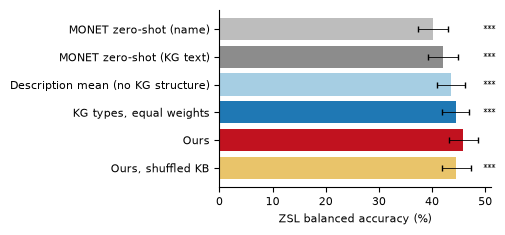

In [10]:
ms_ = [m for m in ZSL_METHODS if m in set(Z['method'])]
v = Z.groupby('method')['zsl_bacc'].agg(['mean', 'std']).reindex(ms_) * 100
fig, ax = plt.subplots(figsize=(3.5, 2.3))
ax.barh(range(len(v)), v['mean'], xerr=v['std'].fillna(0), color=[PAL[m] for m in ms_], error_kw=dict(lw=0.6, capsize=2))
for i, m in enumerate(ms_):
    if m != 'ours' and 'ours' in ms_:
        p = paired('ours', m)['p']
        star = '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else 'n.s.'
        ax.text(v['mean'].max() + v['std'].max() + 1, i, star, va='center', fontsize=6)
ax.set_yticks(range(len(v)), [NAMES[m] for m in ms_]); ax.invert_yaxis()
ax.set_xlabel('ZSL balanced accuracy (%)')
savefig(fig, 'fig1_prompt_zsl'); plt.show()

### Fig. 2 Learned relation-type weights

saved figures_v2c\fig2_type_weights.pdf


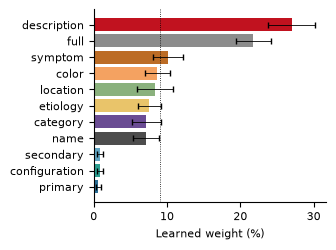

In [11]:
W = np.array(Z[Z['method'] == 'ours']['type_weight'].tolist()) * 100
o = np.argsort(-W.mean(0))
fig, ax = plt.subplots(figsize=(3.0, 2.5))
ax.barh(range(len(o)), W.mean(0)[o], xerr=W.std(0)[o], color=[TYPE_COL[TYPES[i]] for i in o], error_kw=dict(lw=0.6, capsize=2))
ax.set_yticks(range(len(o)), [TYPES[i] for i in o]); ax.invert_yaxis()
ax.axvline(100 / len(TYPES), ls=':', c='k', lw=0.6); ax.set_xlabel('Learned weight (%)')
savefig(fig, 'fig2_type_weights'); plt.show()

### Fig. 3 Learned pooling temperature per type (low = max-like: only some attributes need to be visible)

saved figures_v2c\fig3_type_temperature.pdf


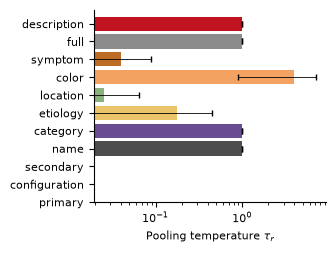

In [12]:
Tau = np.array(Z[Z['method'] == 'ours']['tau'].tolist())
fig, ax = plt.subplots(figsize=(3.0, 2.5))
ax.barh(range(len(TYPES)), Tau.mean(0)[o], xerr=Tau.std(0)[o], color=[TYPE_COL[TYPES[i]] for i in o],
        error_kw=dict(lw=0.6, capsize=2))
ax.set_yticks(range(len(TYPES)), [TYPES[i] for i in o]); ax.invert_yaxis(); ax.set_xscale('log')
ax.set_xlabel('Pooling temperature $\\tau_r$')
savefig(fig, 'fig3_type_temperature'); plt.show()

### Fig. 4 Leave-one-type-out ablation

saved figures_v2c\fig4_prompt_ablation.pdf


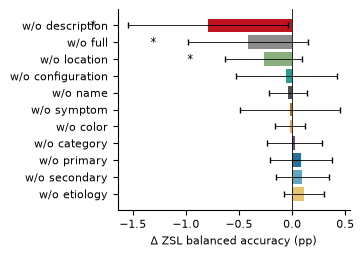

In [13]:
if ABLATION:
    full = Z[Z['method'] == 'ours'].set_index('split')['zsl_bacc']; rows = []
    for t in TYPES:
        a = Z[Z['method'] == f'w/o {t}'].set_index('split')['zsl_bacc']
        d = (a - full.reindex(a.index)) * 100
        p = ttest_rel(a, full.reindex(a.index)).pvalue if len(d) > 1 else 1
        rows.append((t, d.mean(), d.std(), p))
    rows.sort(key=lambda r: r[1])
    fig, ax = plt.subplots(figsize=(3.0, 2.6))
    ax.barh(range(len(rows)), [r[1] for r in rows], xerr=[r[2] for r in rows], color=[TYPE_COL[r[0]] for r in rows],
            error_kw=dict(lw=0.6, capsize=2))
    for i, r in enumerate(rows):
        if r[3] < 0.05:
            ax.text(r[1] - r[2] - 0.3 if r[1] < 0 else r[1] + r[2] + 0.3, i, '*', va='center',
                    ha='right' if r[1] < 0 else 'left')
    ax.set_yticks(range(len(rows)), [f'w/o {r[0]}' for r in rows]); ax.invert_yaxis()
    ax.axvline(0, c='k', lw=0.6); ax.set_xlabel('$\\Delta$ ZSL balanced accuracy (pp)')
    savefig(fig, 'fig4_prompt_ablation'); plt.show()

### Fig. 5 Per-class accuracy on unseen diseases: name prompt vs. ours (all splits)

improved 70% | equal 6% | worse 25%
saved figures_v2c\fig5_prompt_per_class.pdf


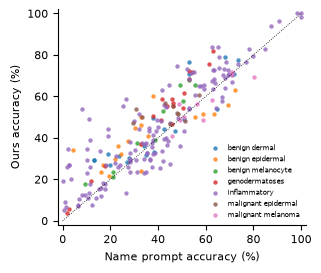

In [14]:
pts = []
for k in range(N_SPLITS):
    a = Z[(Z['method'] == 'name') & (Z['split'] == k)]['per_class_unseen']
    b = Z[(Z['method'] == 'ours') & (Z['split'] == k)]['per_class_unseen']
    if len(a) and len(b):
        a, b = a.iloc[0], b.iloc[0]; pts += [(a[c], b[c], cat_of[int(c)]) for c in a if c in b]
P_ = pd.DataFrame(pts, columns=['name', 'ours', 'cat'])
fig, ax = plt.subplots(figsize=(3.2, 2.8)); cmap = plt.get_cmap('tab10')
for i, (c, g) in enumerate(P_.groupby('cat')):
    ax.scatter(g['name'] * 100, g['ours'] * 100, s=10, color=cmap(i), label=c, alpha=0.8, lw=0)
ax.plot([0, 100], [0, 100], c='k', lw=0.6, ls=':')
ax.set(xlabel='Name prompt accuracy (%)', ylabel=f'{OURS} accuracy (%)', xlim=(-2, 102), ylim=(-2, 102))
ax.legend(fontsize=5, frameon=False, loc='lower right')
print(f"improved {(P_.ours > P_.name).mean():.0%} | equal {(P_.ours == P_.name).mean():.0%} | worse {(P_.ours < P_.name).mean():.0%}")
savefig(fig, 'fig5_prompt_per_class'); plt.show()

### Fig. 6 GZSL seen-unseen curve (split 0)

saved figures_v2c\fig6_prompt_gzsl.pdf


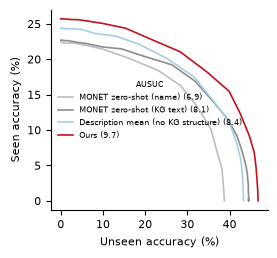

In [15]:
fig, ax = plt.subplots(figsize=(2.8, 2.6))
for m in [x for x in ('name', 'kg_text', 'desc_mean', 'ours') if x in set(Z['method'])]:
    r = Z[(Z['method'] == m) & (Z['split'] == 0)].iloc[0]; c = np.array(r['curve']) * 100
    ax.plot(c[:, 1], c[:, 0], c=PAL[m], lw=1.2, label=f"{NAMES[m]} ({r['ausuc'] * 100:.1f})")
ax.set_xlabel('Unseen accuracy (%)'); ax.set_ylabel('Seen accuracy (%)'); ax.legend(fontsize=5.5, frameon=False, title='AUSUC', title_fontsize=6)
savefig(fig, 'fig6_prompt_gzsl'); plt.show()

### Case studies (split 0)

Unseen-test images that the attribute prompts classify correctly while the name prompt does not. Right panel: the true disease's KG sentences ranked by how strongly this image matches them, as a z-score against the same sentence's scores on all unseen-test images (which KG attributes are visible here). One figure per case.

In [16]:
sp0 = SPLITS[0]
ours0 = make('ours', 0).to(DEVICE); ours0.load_state_dict(torch.load(RES / 'ours_split0.pt', map_location=DEVICE)); ours0.eval()
name0 = make('name', 0).to(DEVICE)
u0 = sp0['unseen']; ut = torch.as_tensor(u0); te = sp0['te_u']; yu = y[te]
Lo, Ln = predict(ours0, te)[:, ut], predict(name0, te)[:, ut]
Po = torch.softmax(Lo, 1).numpy()
ok = (u0[Lo.argmax(1).numpy()] == yu) & (u0[Ln.argmax(1).numpy()] != yu)
cand = np.where(ok)[0]; cand = cand[np.argsort(-Po[cand].max(1))]
picked, used = [], set()
for i in cand:
    if yu[i] not in used:
        picked.append(i); used.add(yu[i])
    if len(picked) == N_CASES:
        break
with torch.no_grad():
    S_te = (Xt[torch.as_tensor(te, device=DEVICE)] @ E_OWN.T).cpu().numpy()
Zs = (S_te - S_te.mean(0)) / (S_te.std(0) + 1e-8)
print('cases:', [dname[yu[i]] for i in picked])

def case_figure(i, name):
    d = yu[i]; top = np.argsort(-Po[i])[:3]
    rows = SENT[(SENT['disease_id'] == d) & SENT['type'].isin(ATTR_TYPES)]
    z = Zs[i, rows.index.to_numpy()]; o = np.argsort(-z)[:8]; r = rows.iloc[o]
    fig, ax = plt.subplots(1, 3, figsize=(7.2, 2.2), gridspec_kw=dict(width_ratios=[1, 1.1, 1.5]))
    ax[0].imshow(Image.open(img_path[te[i]]).convert('RGB')); ax[0].axis('off'); ax[0].set_title(f'True: {dname[d]}', fontsize=7)
    ax[1].barh(range(3), Po[i][top] * 100, color=['#c1121f' if u0[t] == d else '#bdbdbd' for t in top])
    ax[1].set_yticks(range(3), [dname[u0[t]] for t in top], fontsize=6); ax[1].invert_yaxis()
    ax[1].set_xlabel('Probability (%)'); ax[1].set_title('Top-3 among unseen', fontsize=7)
    lab = [f"{t}: {v[:28] + ('...' if len(v) > 28 else '')}" for t, v in zip(r['type'], r['value'])]
    ax[2].barh(range(len(r)), z[o], color=[TYPE_COL[t] for t in r['type']])
    ax[2].set_yticks(range(len(r)), lab, fontsize=5.5); ax[2].invert_yaxis(); ax[2].axvline(0, c='k', lw=0.5)
    ax[2].set_xlabel('Match strength (z-score)'); ax[2].set_title('KG attributes visible in this image', fontsize=7)
    plt.tight_layout(); savefig(fig, name); plt.show()

cases: ['fordyce spots', 'naevus comedonicus', 'juvenile xanthogranuloma']


saved figures_v2c\fig7_case1.pdf


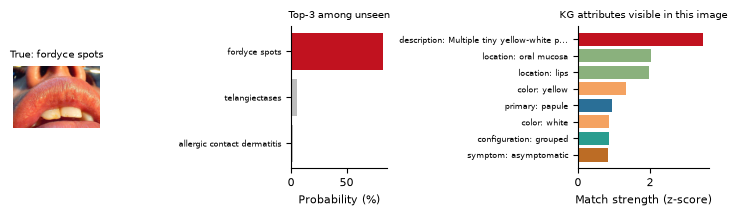

In [17]:
if len(picked) > 0:
    case_figure(picked[0], 'fig7_case1')

saved figures_v2c\fig7_case2.pdf


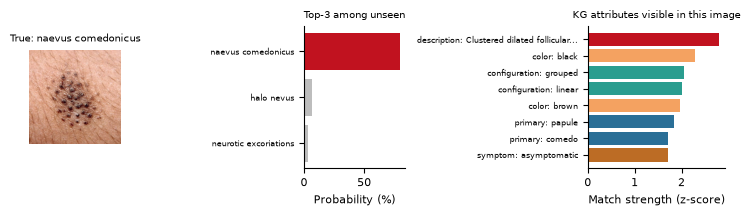

In [18]:
if len(picked) > 1:
    case_figure(picked[1], 'fig7_case2')

saved figures_v2c\fig7_case3.pdf


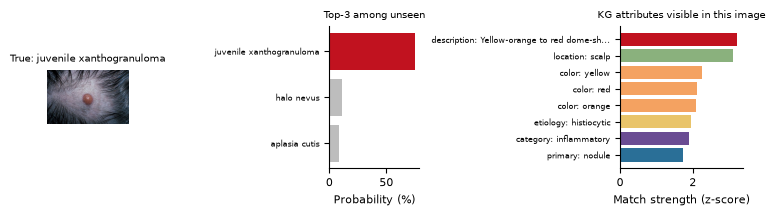

In [19]:
if len(picked) > 2:
    case_figure(picked[2], 'fig7_case3')